# Lab04 — Feature Selection cho bài toán House Price Prediction

**Dataset:** Kaggle *House Prices — Advanced Regression Techniques* (`train.csv`, có nhãn `SalePrice`)  
**Models:** SVR · XGBoost · Random Forest  
**Feature Selection:** Filter (Pearson, Mutual Information) · Wrapper (RFE/RFECV) · Embedded (XGBoost importance)

Quy trình tổng quát:

```text
Dataset → Preprocessing → Train/Test Split → Baseline → Feature Selection → Train Model → Evaluate → Compare
```

**Nguyên tắc chống Data Leakage của notebook này**

- Mọi bộ chọn feature (Pearson, MI, RFE, XGBoost importance) chỉ được `fit` trên **training set**. Test set chỉ dùng để báo cáo kết quả cuối.
- Khi chọn số lượng feature K, notebook dùng **5-fold CV bên trong training set** và **tính lại ranking trong từng fold** (ranking chỉ nhìn thấy phần train của fold, không thấy phần validation của fold).
- K tốt nhất được chọn **chỉ dựa trên CV RMSE**. Các đường cong theo Test được vẽ để phân tích, không dùng để chọn.
- Tại sao fit selector trên toàn bộ dataset trước khi split là sai? Vì ranking khi đó đã "nhìn thấy" `SalePrice` của các mẫu test; tập feature được chọn thiên về những feature tình cờ tương quan với nhãn của test, nên sai số test bị đánh giá thấp hơn thực tế (optimistic bias) và không phản ánh khả năng tổng quát hoá.

## 1. Import Libraries

In [13]:
import time, warnings, json
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression, RFE, RFECV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 30)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
TOLERANCE = 0.01
MODEL_NAMES = ['SVR', 'XGBoost', 'Random Forest']

OUT_DIR = Path('outputs'); FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load Dataset
Đọc `train.csv` (file duy nhất có nhãn `SalePrice`). `test.csv` của Kaggle không có nhãn nên không dùng để đánh giá; tập test của bài lab được tách từ `train.csv`.

In [14]:
candidates = ['/mnt/user-data/uploads/train.csv', 'train.csv', 'data/train.csv']
DATA_PATH = next(p for p in candidates if Path(p).exists())
raw = pd.read_csv(DATA_PATH)
print('Nguồn dữ liệu:', DATA_PATH)
print('Shape:', raw.shape)
raw.head()

Nguồn dữ liệu: train.csv
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Exploratory Data Analysis

In [15]:
print(raw.dtypes.value_counts().to_string())
num_raw = raw.select_dtypes(include='number').columns.drop(['Id', 'SalePrice'])
cat_raw = raw.select_dtypes(exclude='number').columns
print(f'\nNumerical features: {len(num_raw)} | Categorical features: {len(cat_raw)}')

missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display(pd.DataFrame({'Missing': missing, 'Pct (%)': (missing / len(raw) * 100).round(2)}))
print('Duplicated rows:', raw.duplicated().sum(), '| Duplicated Id:', raw['Id'].duplicated().sum())

str        43
int64      35
float64     3

Numerical features: 36 | Categorical features: 43


,Missing,Pct (%)
PoolQC,1453,99.5200
MiscFeature,1406,96.3000
Alley,1369,93.7700
Fence,1179,80.7500
MasVnrType,872,59.7300
FireplaceQu,690,47.2600
LotFrontage,259,17.7400
GarageType,81,5.5500
GarageYrBlt,81,5.5500
GarageFinish,81,5.5500


Duplicated rows: 0 | Duplicated Id: 0


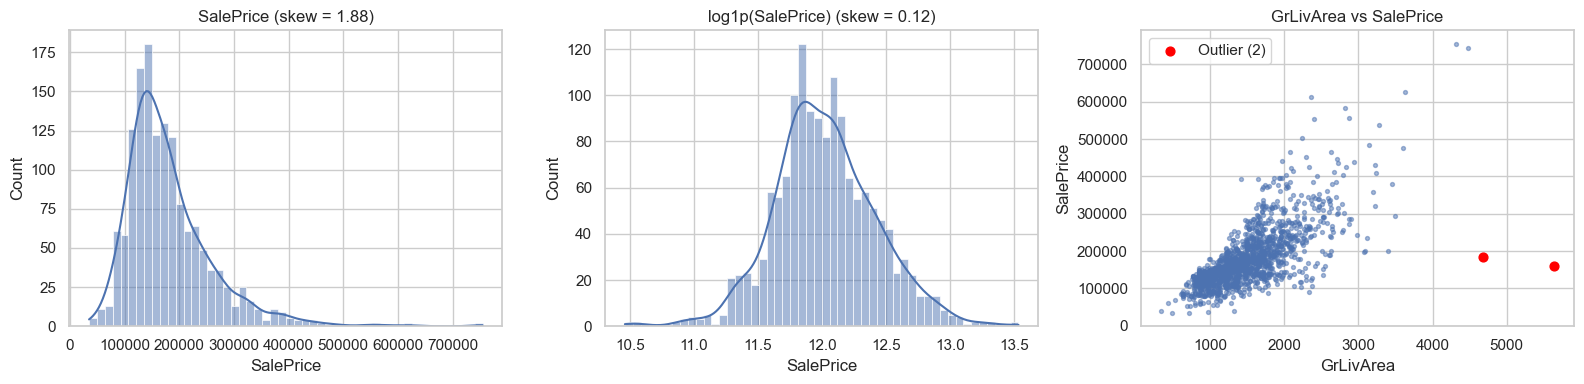

In [16]:
outlier_mask = (raw['GrLivArea'] > 4000) & (raw['SalePrice'] < 300000)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw['SalePrice'], bins=50, kde=True, ax=ax[0]); ax[0].set_title(f"SalePrice (skew = {raw['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(raw['SalePrice']), bins=50, kde=True, ax=ax[1]); ax[1].set_title(f"log1p(SalePrice) (skew = {np.log1p(raw['SalePrice']).skew():.2f})")
ax[2].scatter(raw['GrLivArea'], raw['SalePrice'], s=8, alpha=.5)
ax[2].scatter(raw.loc[outlier_mask, 'GrLivArea'], raw.loc[outlier_mask, 'SalePrice'], color='red', s=40, label=f'Outlier ({outlier_mask.sum()})')
ax[2].set_xlabel('GrLivArea'); ax[2].set_ylabel('SalePrice'); ax[2].legend(); ax[2].set_title('GrLivArea vs SalePrice')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_target_outliers.png', dpi=150); plt.show()

`SalePrice` lệch phải mạnh nên mô hình được huấn luyện trên `log1p(SalePrice)`; mọi metric (RMSE, MAE, R²) được tính lại trên thang giá gốc (USD) để dễ diễn giải. Hai điểm `GrLivArea > 4000` nhưng giá thấp là outlier đã được tác giả dataset khuyến nghị loại bỏ (quy tắc cố định, không phụ thuộc phân phối dữ liệu nên không gây leakage).

## 4. Data Preprocessing
Chia thành 2 bước: (a) làm sạch **xác định** (không học tham số từ dữ liệu) thực hiện trước split; (b) imputation và one-hot **có học tham số** được fit chỉ trên training set.

In [17]:
NONE_COLS = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
QUAL = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ORDINAL_MAPS = {c: QUAL for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                                  'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']}
ORDINAL_MAPS['BsmtExposure'] = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
ORDINAL_MAPS['BsmtFinType1'] = ORDINAL_MAPS['BsmtFinType2'] = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
ORDINAL_MAPS['GarageFinish'] = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}

def clean_raw(df):
    df = df.drop(columns='Id').copy()
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    df[NONE_COLS] = df[NONE_COLS].fillna('None')
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    for col, mapping in ORDINAL_MAPS.items():
        df[col] = df[col].map(mapping)
    return df

data = raw.loc[~outlier_mask].reset_index(drop=True)
X = clean_raw(data.drop(columns='SalePrice'))
y = np.log1p(data['SalePrice'])
print(f'Loại {outlier_mask.sum()} outlier -> {len(data)} mẫu | {X.shape[1]} cột trước encoding')
print('Missing còn lại (sẽ imputation trong preprocessor):', X.isna().sum()[X.isna().sum() > 0].to_dict())

Loại 2 outlier -> 1458 mẫu | 79 cột trước encoding
Missing còn lại (sẽ imputation trong preprocessor): {'LotFrontage': 259, 'Electrical': 1}


Quy ước xử lý: `NA` trong các cột như `PoolQC`, `Alley`, `BsmtQual`, `Garage*`... nghĩa là *không có hạng mục đó* (theo data description) nên điền `None`; các cột chất lượng có thứ bậc được mã hoá ordinal; `MSSubClass` là mã nhóm nên coi là categorical. Phần missing còn lại (ví dụ `LotFrontage`, `Electrical`) dùng median/most-frequent được fit trên training set.

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("X:", X.shape)
print("y:", y.shape)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X: (1458, 79)
y: (1458,)
X_train: (1166, 79)
X_test : (292, 79)
y_train: (1166,)
y_test : (292,)


In [19]:
print("===== DATA SHAPE =====")
print("X:", X.shape)
print("y:", y.shape)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\n===== TARGET =====")
print("Target: SalePrice")
print("y đã log1p:", True)

print("\n===== FEATURE =====")
print("Số feature sau preprocessing:", X_train.shape[1])

print("\n===== MISSING =====")
print("X_train missing:", X_train.isna().sum().sum())
print("X_test missing :", X_test.isna().sum().sum())

print("\n===== DUPLICATE FEATURE NAMES =====")
print("Tên feature trùng:", X_train.columns.duplicated().sum())

===== DATA SHAPE =====
X: (1458, 79)
y: (1458,)
X_train: (1166, 79)
X_test : (292, 79)
y_train: (1166,)
y_test : (292,)

===== TARGET =====
Target: SalePrice
y đã log1p: True

===== FEATURE =====
Số feature sau preprocessing: 79

===== MISSING =====
X_train missing: 214
X_test missing : 46

===== DUPLICATE FEATURE NAMES =====
Tên feature trùng: 0


## 5. Train/Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(exclude='number').columns
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
constant_cols = X_train.columns[X_train.nunique() <= 1]
X_train, X_test = X_train.drop(columns=constant_cols), X_test.drop(columns=constant_cols)
y_train_usd, y_test_usd = np.expm1(y_train), np.expm1(y_test)
N_FEATURES = X_train.shape[1]

print(f'Train: {X_train.shape} | Test: {X_test.shape} | Số feature sau preprocessing: {N_FEATURES}')
print(f'Numerical: {len(num_cols)} (gồm cột ordinal) | Categorical gốc: {len(cat_cols)} -> one-hot | Bỏ cột hằng số: {len(constant_cols)}')
print('Missing sau preprocessing (train/test):', int(X_train.isna().sum().sum()), '/', int(X_test.isna().sum().sum()))

Train: (1166, 253) | Test: (292, 253) | Số feature sau preprocessing: 253
Numerical: 49 (gồm cột ordinal) | Categorical gốc: 30 -> one-hot | Bỏ cột hằng số: 0
Missing sau preprocessing (train/test): 0 / 0


Preprocessor được `fit` chỉ trên `X_train` rồi `transform` cho `X_test`. `StandardScaler` **không** áp dụng ở đây mà nằm trong pipeline của SVR (xem mục 6), vì SVR dùng kernel RBF dựa trên khoảng cách nên nhạy với thang đo; XGBoost và Random Forest dựa trên ngưỡng chia cây, bất biến với phép biến đổi đơn điệu của feature nên không cần scale.

## 6. Baseline Models

- **SVR (RBF kernel):** hồi quy trong ống ε-insensitive; siêu tham số chính `C` (mức phạt sai số), `epsilon` (độ rộng ống không phạt), `gamma` (độ rộng kernel; giữ `'scale'` để tự co giãn theo số feature). Bắt buộc `StandardScaler` vì kernel RBF dùng khoảng cách Euclid.
- **XGBoost:** Gradient Boosting — cộng dần các cây quyết định nông, mỗi cây sửa phần dư (gradient của loss) của tổ hợp trước, có regularization.
- **Random Forest:** Bagging — nhiều cây sâu huấn luyện trên bootstrap và tập con feature ngẫu nhiên, dự đoán lấy trung bình.

Siêu tham số của mỗi model được **tune một lần bằng GridSearchCV 5-fold trên training set với toàn bộ feature** (tiêu chí RMSE trên `log1p(SalePrice)`), sau đó giữ **cố định** cho mọi thí nghiệm Top-K để so sánh công bằng. Các tham số phụ thuộc số feature được viết dạng tỉ lệ (`gamma='scale'`, `max_features` là phân số, `colsample_bytree` là phân số).

In [21]:
BASE_PARAMS = {
    'SVR': {},
    'XGBoost': dict(subsample=0.8, colsample_bytree=0.5),
    'Random Forest': dict(n_estimators=200),
}
GRIDS = {
    'SVR': {'svr__C': [1, 3, 10, 30, 100], 'svr__epsilon': [0.01, 0.05, 0.1]},
    'XGBoost': {'max_depth': [3, 4], 'learning_rate': [0.03, 0.06], 'n_estimators': [300, 600]},
    'Random Forest': {'max_features': [0.2, 0.33, 0.5], 'min_samples_leaf': [1, 2]},
}

def make_model(name, **params):
    params = {**BASE_PARAMS[name], **params}
    if name == 'SVR':
        return make_pipeline(StandardScaler(), SVR(kernel='rbf', gamma='scale', **params))
    if name == 'XGBoost':
        return XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, tree_method='hist', **params)
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **params)

cv = KFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
best_params, tuning_rows = {}, []
for name in MODEL_NAMES:
    gs = GridSearchCV(make_model(name), GRIDS[name], cv=cv, scoring='neg_root_mean_squared_error')
    t0 = time.perf_counter(); gs.fit(X_train, y_train)
    best_params[name] = {k.split('__')[-1]: v for k, v in gs.best_params_.items()}
    tuning_rows.append({'Model': name, 'Best_Params': best_params[name], 'CV_RMSLE': -gs.best_score_,
                        'Grid_Size': len(gs.cv_results_['params']), 'Tuning_Time': time.perf_counter() - t0})
tuning_df = pd.DataFrame(tuning_rows)
tuning_df

,Model,Best_Params,CV_RMSLE,Grid_Size,Tuning_Time
0,SVR,"{'C': 1, 'epsilon': 0.01}",0.1867,15,10.5072
1,XGBoost,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.1161,8,56.0986
2,Random Forest,"{'max_features': 0.33, 'min_samples_leaf': 1}",0.1331,6,75.9981


In [22]:
def calculate_metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {'RMSE': float(np.sqrt(mean_squared_error(yt, yp))), 'MAE': float(mean_absolute_error(yt, yp)),
            'R2': float(r2_score(yt, yp)), 'RMSLE': float(np.sqrt(mean_squared_error(y_true_log, y_pred_log)))}

def evaluate_model(name, X_tr, y_tr, X_te, y_te):
    model = make_model(name, **best_params[name])
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); train_time = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(X_te); infer_time = time.perf_counter() - t0
    return {**calculate_metrics(y_te, pred), 'Training_Time': train_time, 'Inference_Time': infer_time}

def cv_metrics(name, X_tr, y_tr):
    folds = [evaluate_model(name, X_tr.iloc[a], y_tr.iloc[a], X_tr.iloc[b], y_tr.iloc[b]) for a, b in cv.split(X_tr)]
    f = pd.DataFrame(folds)
    return {'CV_RMSE': f.RMSE.mean(), 'CV_RMSE_std': f.RMSE.std(), 'CV_MAE': f.MAE.mean(), 'CV_R2': f.R2.mean()}

## 7. Baseline Evaluation
Baseline dùng toàn bộ feature hợp lệ sau preprocessing, cùng siêu tham số đã tune bằng CV, đánh giá bằng CV (trên train) và một lần trên test.

In [23]:
baseline_rows = []
for name in MODEL_NAMES:
    res = evaluate_model(name, X_train, y_train, X_test, y_test)
    baseline_rows.append({'Model': name, 'Num_Features': N_FEATURES, **{k: res[k] for k in ['RMSE', 'MAE', 'R2', 'RMSLE', 'Training_Time', 'Inference_Time']},
                          **cv_metrics(name, X_train, y_train), 'Params': str(best_params[name])})
baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(OUT_DIR / 'baseline_results.csv', index=False)
baseline_df.drop(columns='Params')

,Model,Num_Features,RMSE,MAE,R2,RMSLE,Training_Time,Inference_Time,CV_RMSE,CV_RMSE_std,CV_MAE,CV_R2
0,SVR,253,"33,133.7719","19,486.6295",0.8012,0.1934,0.1732,0.0511,"40,169.7863","10,195.4738","19,894.5337",0.7431
1,XGBoost,253,"18,922.0995","13,945.9571",0.9352,0.1113,1.0519,0.0169,"23,502.1241","3,340.6349","14,320.7107",0.9136
2,Random Forest,253,"22,715.9678","15,778.9125",0.9066,0.1377,4.9847,0.0911,"27,591.0187","3,691.0398","16,541.8166",0.8810


In [31]:
print("MODEL_NAMES:", MODEL_NAMES)
print("N_FEATURES:", N_FEATURES)
print("best_params:", best_params)
print("OUT_DIR:", OUT_DIR)

MODEL_NAMES: ['SVR', 'XGBoost', 'Random Forest']
N_FEATURES: 253
best_params: {'SVR': {'C': 1, 'epsilon': 0.01}, 'XGBoost': {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 600}, 'Random Forest': {'max_features': 0.33, 'min_samples_leaf': 1}}
OUT_DIR: outputs


## 8. Feature Selection
Bốn bộ xếp hạng, mỗi bộ là một hàm nhận `(X, y)` của **dữ liệu train** và trả về danh sách feature từ quan trọng nhất đến kém nhất. Sau one-hot mọi feature đều là số nên Pearson/MI áp dụng trực tiếp; với dummy nhị phân, Pearson chính là point-biserial correlation, và MI được tính với `discrete_features=True` cho các cột nhị phân. Ranking dùng `y = log1p(SalePrice)`, cùng thang với mục tiêu huấn luyện.

In [24]:
def rank_pearson(X, y):
    return X.corrwith(y).fillna(0).abs().sort_values(ascending=False, kind='stable').index.tolist()

def rank_mi(X, y):
    mi = mutual_info_regression(X, y, discrete_features=(X.nunique() <= 2).values, random_state=RANDOM_STATE)
    return pd.Series(mi, index=X.columns).sort_values(ascending=False, kind='stable').index.tolist()

def rank_xgb_importance(X, y):
    model = make_model('XGBoost', **best_params['XGBoost'], importance_type='gain').fit(X, y)
    return pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False, kind='stable').index.tolist()

def rank_rfe(X, y):
    estimator = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                             random_state=RANDOM_STATE, n_jobs=1, tree_method='hist')
    rfe = RFE(estimator, n_features_to_select=1, step=3).fit(X, y)
    return pd.Series(rfe.ranking_, index=X.columns).sort_values(kind='stable').index.tolist()

RANKERS = {'Pearson': rank_pearson, 'Mutual Information': rank_mi, 'RFE (XGBoost)': rank_rfe, 'XGBoost Importance': rank_xgb_importance}

### 8.1 Filter Methods
Filter chấm điểm từng feature độc lập với model, nhanh và không tốn huấn luyện; nhược điểm là bỏ qua tương tác giữa feature và sự dư thừa (hai feature tương quan cao đều có điểm cao).

In [25]:
final_order = {}
t0 = time.perf_counter(); final_order['Pearson'] = rank_pearson(X_train, y_train); t_p = time.perf_counter() - t0
t0 = time.perf_counter(); final_order['Mutual Information'] = rank_mi(X_train, y_train); t_m = time.perf_counter() - t0
print(f'Thời gian xếp hạng: Pearson {t_p:.2f}s | MI {t_m:.2f}s')

corr = X_train.corrwith(y_train).fillna(0)
pearson_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['Pearson']})
pearson_table['Correlation'] = corr[pearson_table.Feature].values
pearson_table['Absolute Correlation'] = pearson_table['Correlation'].abs()
mi_scores = pd.Series(mutual_info_regression(X_train, y_train, discrete_features=(X_train.nunique() <= 2).values, random_state=RANDOM_STATE), index=X_train.columns)
mi_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['Mutual Information']})
mi_table['MI Score'] = mi_scores[mi_table.Feature].values
display(pearson_table.head(15)); display(mi_table.head(15))

Thời gian xếp hạng: Pearson 0.21s | MI 6.48s


,Rank,Feature,Correlation,Absolute Correlation
0,1,OverallQual,0.8135,0.8135
1,2,GrLivArea,0.7310,0.7310
2,3,GarageCars,0.6882,0.6882
3,4,KitchenQual,0.6788,0.6788
4,5,ExterQual,0.6733,0.6733
5,6,GarageArea,0.6642,0.6642
6,7,TotalBsmtSF,0.6502,0.6502
7,8,1stFlrSF,0.6155,0.6155
8,9,GarageFinish,0.6116,0.6116
9,10,BsmtQual,0.6070,0.6070


,Rank,Feature,MI Score
0,1,OverallQual,0.5353
1,2,GrLivArea,0.4745
2,3,GarageArea,0.3819
3,4,TotalBsmtSF,0.3614
4,5,GarageCars,0.3610
5,6,YearBuilt,0.3435
6,7,KitchenQual,0.3176
7,8,ExterQual,0.3103
8,9,1stFlrSF,0.3091
9,10,BsmtQual,0.3044


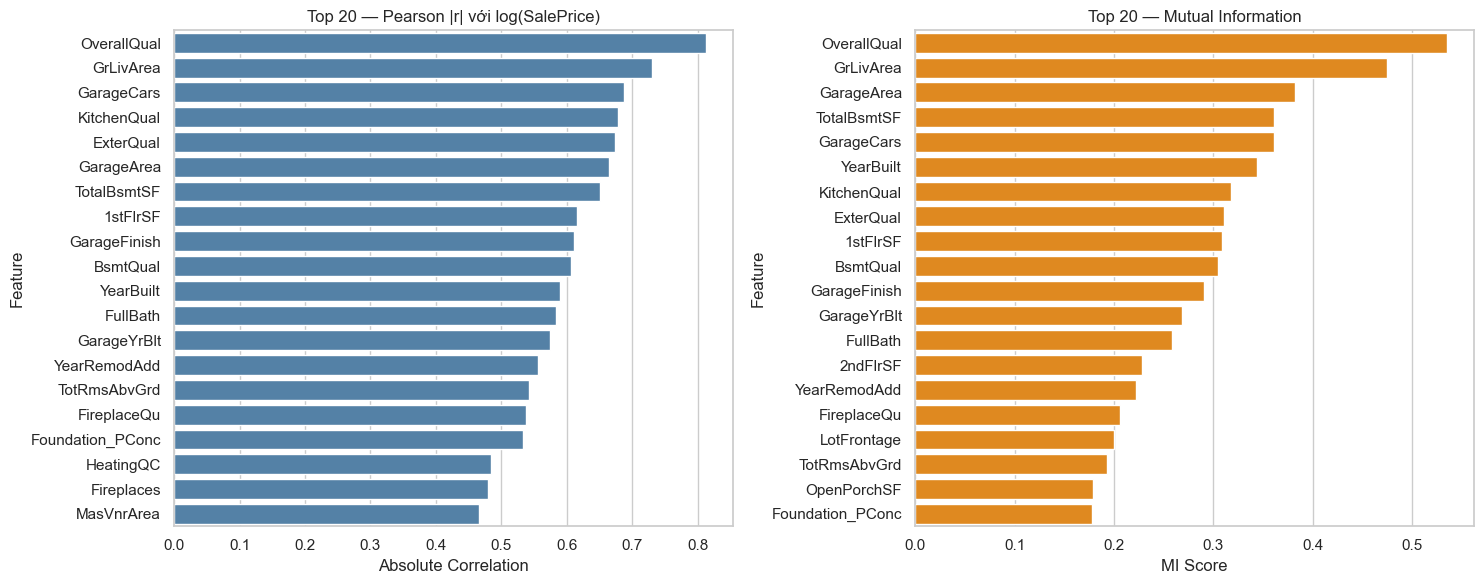

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=pearson_table.head(20), y='Feature', x='Absolute Correlation', color='steelblue', ax=ax[0]); ax[0].set_title('Top 20 — Pearson |r| với log(SalePrice)')
sns.barplot(data=mi_table.head(20), y='Feature', x='MI Score', color='darkorange', ax=ax[1]); ax[1].set_title('Top 20 — Mutual Information')
plt.tight_layout(); plt.savefig(FIG_DIR / 'chart6_filter_top_features.png', dpi=150); plt.show()

### 8.2 Wrapper Methods
Wrapper dùng chính một model làm "hộp đen" để đánh giá tập feature: **RFE** huấn luyện estimator, loại dần các feature có importance thấp nhất (`step=3` feature mỗi vòng) cho đến còn 1, và thứ tự bị loại tạo ra ranking đầy đủ. Vì phải huấn luyện lại model nhiều lần nên tốn thời gian hơn Filter rất nhiều. Estimator là XGBoost nhẹ (100 cây, độ sâu 3) để giảm chi phí; tiêu chí xếp hạng là importance của estimator ở mỗi vòng. Ngoài ra **RFECV** (3-fold CV chỉ trên train, scoring RMSE trên log-target, `step=5`) được chạy một lần để tham khảo số feature tối ưu theo CV của chính wrapper.

In [27]:
t0 = time.perf_counter(); final_order['RFE (XGBoost)'] = rank_rfe(X_train, y_train); t_rfe = time.perf_counter() - t0
print(f'Thời gian RFE trên toàn bộ train: {t_rfe:.1f}s (so với Pearson {t_p:.2f}s, MI {t_m:.2f}s)')

rfecv_est = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                         random_state=RANDOM_STATE, n_jobs=1, tree_method='hist')
t0 = time.perf_counter()
rfecv = RFECV(rfecv_est, step=5, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
              scoring='neg_root_mean_squared_error', min_features_to_select=5).fit(X_train, y_train)
t_rfecv = time.perf_counter() - t0
RFECV_N = int(rfecv.n_features_)
print(f'RFECV chọn {RFECV_N} feature (CV RMSLE = {-rfecv.cv_results_["mean_test_score"].max():.4f}, {t_rfecv:.1f}s)')
rfe_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['RFE (XGBoost)']})
rfe_table.head(15)

Thời gian RFE trên toàn bộ train: 7.1s (so với Pearson 0.21s, MI 6.48s)
RFECV chọn 233 feature (CV RMSLE = 0.1200, 10.3s)


,Rank,Feature
0,1,KitchenQual
1,2,YearBuilt
2,3,GrLivArea
3,4,GarageCars
4,5,OverallQual
5,6,GarageFinish
6,7,CentralAir_N
7,8,TotalBsmtSF
8,9,FireplaceQu
9,10,GarageCond


### 8.3 Embedded Methods
Embedded: việc chọn/đánh giá feature diễn ra **ngay trong quá trình huấn luyện** model. Với XGBoost, mỗi lần chia nút cây chọn feature giảm loss nhiều nhất; tổng *gain* mà feature đóng góp qua toàn bộ các cây chính là importance. Tập feature được xếp hạng chỉ từ model huấn luyện trên train.

Số feature có importance > 0: 177 / 253


,Rank,Feature,Importance (gain)
0,1,ExterQual,0.1695
1,2,OverallQual,0.0956
2,3,KitchenQual,0.0730
3,4,GarageFinish,0.0543
4,5,GarageCars,0.0498
5,6,FireplaceQu,0.0465
6,7,GrLivArea,0.0355
7,8,CentralAir_N,0.0270
8,9,GarageType_None,0.0260
9,10,BsmtQual,0.0256


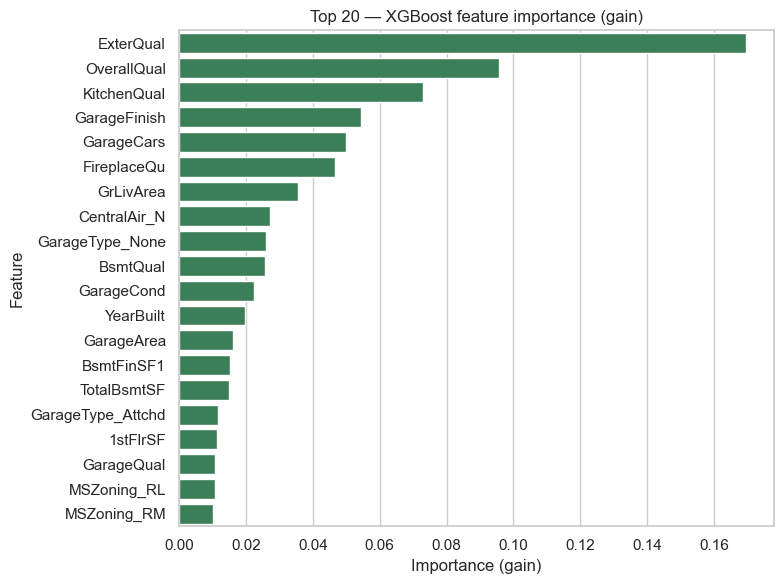

In [28]:
t0 = time.perf_counter(); final_order['XGBoost Importance'] = rank_xgb_importance(X_train, y_train); t_x = time.perf_counter() - t0
xgb_imp_model = make_model('XGBoost', **best_params['XGBoost'], importance_type='gain').fit(X_train, y_train)
xgb_imp = pd.Series(xgb_imp_model.feature_importances_, index=X_train.columns)
xgb_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['XGBoost Importance']})
xgb_table['Importance (gain)'] = xgb_imp[xgb_table.Feature].values
print(f'Số feature có importance > 0: {(xgb_imp > 0).sum()} / {N_FEATURES}')
display(xgb_table.head(15))
plt.figure(figsize=(8, 6)); sns.barplot(data=xgb_table.head(20), y='Feature', x='Importance (gain)', color='seagreen')
plt.title('Top 20 — XGBoost feature importance (gain)'); plt.tight_layout()
plt.savefig(FIG_DIR / 'chart5_xgb_importance.png', dpi=150); plt.show()

## 9. Feature Ranking
Bảng tổng hợp thứ hạng (1 = quan trọng nhất) của 4 phương pháp. **Mean Rank** = trung bình cộng 4 thứ hạng (Borda count, trọng số bằng nhau). Đây chỉ là thước đo tham khảo để so sánh mức đồng thuận giữa các phương pháp: các thí nghiệm Top-K bên dưới dùng ranking riêng của từng phương pháp, **không** dùng Mean Rank.

In [29]:
rank_df = pd.DataFrame({'Feature': X_train.columns})
for name, order in final_order.items():
    rank_df[name + ' Rank'] = rank_df.Feature.map({f: i + 1 for i, f in enumerate(order)})
rank_df.insert(1, 'Pearson_Corr', corr[rank_df.Feature].values)
rank_df['MI_Score'] = mi_scores[rank_df.Feature].values
rank_df['XGB_Importance'] = xgb_imp[rank_df.Feature].values
rank_df['Mean_Rank'] = rank_df[[c for c in rank_df.columns if c.endswith(' Rank')]].mean(axis=1)
rank_df = rank_df.sort_values('Mean_Rank').reset_index(drop=True)
rank_df.to_csv(OUT_DIR / 'feature_rankings.csv', index=False)
display(rank_df.head(15))
rank_cols = [c for c in rank_df.columns if c.endswith(' Rank')]
print('Tương quan hạng Spearman giữa các phương pháp:')
display(rank_df[rank_cols].corr(method='spearman'))
top20 = {n: set(o[:20]) for n, o in final_order.items()}
overlap = pd.DataFrame({a: {b: len(top20[a] & top20[b]) for b in top20} for a in top20})
print('Số feature chung trong Top 20:'); display(overlap)

,Feature,Pearson_Corr,Pearson Rank,Mutual Information Rank,RFE (XGBoost) Rank,XGBoost Importance Rank,MI_Score,XGB_Importance,Mean_Rank
0,OverallQual,0.8135,1,1,5,2,0.5353,0.0956,2.2500
1,GrLivArea,0.7310,2,2,3,7,0.4745,0.0355,3.5000
2,KitchenQual,0.6788,4,7,1,3,0.3176,0.0730,3.7500
3,GarageCars,0.6882,3,5,4,5,0.3610,0.0498,4.2500
4,ExterQual,0.6733,5,8,14,1,0.3103,0.1695,7.0000
5,GarageFinish,0.6116,9,11,6,4,0.2905,0.0543,7.5000
6,YearBuilt,0.5899,11,6,2,12,0.3435,0.0196,7.7500
7,TotalBsmtSF,0.6502,7,4,8,15,0.3614,0.0149,8.5000
8,GarageArea,0.6642,6,3,12,13,0.3819,0.0162,8.5000
9,BsmtQual,0.6070,10,10,11,10,0.3044,0.0256,10.2500


Tương quan hạng Spearman giữa các phương pháp:


,Pearson Rank,Mutual Information Rank,RFE (XGBoost) Rank,XGBoost Importance Rank
Pearson Rank,1.0000,0.8214,0.4683,0.6334
Mutual Information Rank,0.8214,1.0000,0.3429,0.6623
RFE (XGBoost) Rank,0.4683,0.3429,1.0000,0.4522
XGBoost Importance Rank,0.6334,0.6623,0.4522,1.0000


Số feature chung trong Top 20:


,Pearson,Mutual Information,RFE (XGBoost),XGBoost Importance
Pearson,20,17,14,12
Mutual Information,17,20,14,12
RFE (XGBoost),14,14,20,16
XGBoost Importance,12,12,16,20


## 10. Incremental Feature Experiments
Với mỗi phương pháp và mỗi `K` trong danh sách tăng dần (tính từ số feature thực tế `N_FEATURES`, kết thúc bằng toàn bộ feature):

1. **CV (để chọn K):** trong từng fold của training set, ranking được tính lại chỉ từ phần train của fold, lấy Top-K, huấn luyện và đo trên phần validation của fold.
2. **Test (để báo cáo):** ranking tính trên toàn bộ training set, lấy Top-K, huấn luyện trên train, đo trên test.

K tốt nhất của mỗi (phương pháp, model) = **K nhỏ nhất có CV RMSE ≤ (1 + 1%) × CV RMSE thấp nhất**. Ngưỡng 1% được chọn làm tolerance: chênh lệch dưới 1% nhỏ hơn độ lệch chuẩn giữa các fold nên coi là không có ý nghĩa, khi đó ưu tiên mô hình ít feature hơn. Test không tham gia vào việc chọn K.

In [30]:
K_LIST = sorted({k for k in [5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200] if k < N_FEATURES} | {N_FEATURES})
print('K list:', K_LIST)

def run_feature_experiment(method, ranker, order, ks=K_LIST):
    cv_rows = []
    for fold, (a, b) in enumerate(cv.split(X_train)):
        Xa, Xb, ya, yb = X_train.iloc[a], X_train.iloc[b], y_train.iloc[a], y_train.iloc[b]
        fold_order = ranker(Xa, ya)
        for k in ks:
            for name in MODEL_NAMES:
                res = evaluate_model(name, Xa[fold_order[:k]], ya, Xb[fold_order[:k]], yb)
                cv_rows.append({'Model': name, 'Num_Features': k, **res})
    cv_df = (pd.DataFrame(cv_rows).groupby(['Model', 'Num_Features'])
             .agg(CV_RMSE=('RMSE', 'mean'), CV_RMSE_std=('RMSE', 'std'), CV_MAE=('MAE', 'mean'), CV_R2=('R2', 'mean')).reset_index())
    rows = []
    for k in ks:
        for name in MODEL_NAMES:
            cols = order[:k]
            res = evaluate_model(name, X_train[cols], y_train, X_test[cols], y_test)
            rows.append({'Method': method, 'Model': name, 'Num_Features': k, **res})
    return pd.DataFrame(rows).merge(cv_df, on=['Model', 'Num_Features'])

results = []
for method, ranker in RANKERS.items():
    t0 = time.perf_counter()
    results.append(run_feature_experiment(method, ranker, final_order[method]))
    print(f'{method}: xong sau {time.perf_counter() - t0:.0f}s')
fs_results = pd.concat(results, ignore_index=True)
FS_COLS = ['Method', 'Model', 'Num_Features', 'RMSE', 'MAE', 'R2', 'Training_Time', 'CV_RMSE', 'CV_RMSE_std', 'CV_MAE', 'CV_R2', 'RMSLE', 'Inference_Time']
fs_results = fs_results[FS_COLS]
fs_results.to_csv(OUT_DIR / 'feature_selection_results.csv', index=False)
print(fs_results.shape)

K list: [5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 253]
Pearson: xong sau 221s


KeyboardInterrupt: 

## 11. SVR Experiments
Kết quả Top-K của SVR theo từng phương pháp (CV RMSE dùng để chọn; Test RMSE chỉ để tham chiếu).

In [ ]:
def pivot_view(model, value):
    return fs_results[fs_results.Model == model].pivot(index='Num_Features', columns='Method', values=value)
for value in ['CV_RMSE', 'RMSE']:
    print(f'SVR — {value}'); display(pivot_view('SVR', value))

SVR — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"31,558.6169","37,815.3769","35,755.5084","41,319.1383"
10,"32,160.7061","32,197.5735","33,125.5754","33,743.3080"
15,"31,539.7913","31,179.5827","29,931.4224","32,852.7821"
20,"32,651.2901","34,324.4863","30,180.1157","32,270.2447"
25,"30,565.5863","32,700.2629","30,192.1742","30,355.9550"
30,"31,969.8777","31,680.6194","31,288.3753","29,681.1373"
40,"31,668.6533","31,447.1779","31,594.8099","33,175.3778"
50,"30,248.8948","31,364.2440","33,307.8021","32,765.6349"
75,"30,713.5996","32,578.8004","35,710.4296","33,471.3637"


SVR — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"28,575.5383","30,124.5790","30,124.5790","29,232.9424"
10,"26,298.6612","28,199.8446","26,924.6822","29,446.1602"
15,"25,642.2881","26,010.6296","25,662.9187","27,430.4029"
20,"27,215.0100","26,594.3365","24,677.1141","25,996.4880"
25,"24,186.9437","27,189.0689","22,670.4478","24,198.2996"
30,"22,776.4163","26,374.3819","21,148.3114","22,878.4225"
40,"23,522.4392","25,088.7090","22,247.6702","20,631.0526"
50,"22,603.8122","26,440.2488","22,237.8229","20,539.1165"
75,"23,233.1982","23,929.2781","30,808.9344","24,993.2536"


## 12. XGBoost Experiments

In [ ]:
for value in ['CV_RMSE', 'RMSE']:
    print(f'XGBoost — {value}'); display(pivot_view('XGBoost', value))

XGBoost — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"31,689.4454","34,537.8736","34,278.6561","39,935.4339"
10,"28,989.3838","29,554.8484","30,327.0813","31,574.5181"
15,"28,367.5456","27,956.7315","26,614.9849","30,012.1908"
20,"27,580.2530","27,304.3025","25,273.6159","27,930.3167"
25,"25,910.5381","27,014.6452","24,781.1909","27,330.2825"
30,"24,580.0820","26,062.1229","24,379.7155","26,492.5120"
40,"24,559.8692","25,666.7479","24,070.2155","23,989.7139"
50,"24,775.6443","25,716.2327","23,911.3112","23,368.7049"
75,"24,381.5509","25,159.1793","23,985.2807","23,009.7398"


XGBoost — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"27,871.6632","29,223.9692","29,528.5204","29,543.0688"
10,"24,567.3425","27,197.7126","25,031.0828","27,132.0888"
15,"25,228.1335","25,384.5793","24,313.3578","25,860.3595"
20,"26,287.5683","25,294.8663","23,808.3831","23,857.1259"
25,"23,542.7549","24,280.0635","21,387.5153","22,701.6281"
30,"21,967.5464","24,278.9889","19,557.3211","21,313.0157"
40,"21,728.4319","22,077.1253","19,136.8267","19,089.2807"
50,"20,837.5421","21,738.3437","19,780.3543","18,452.1303"
75,"20,732.9828","21,170.9314","18,827.7763","19,329.1771"


## 13. Random Forest Experiments

In [ ]:
for value in ['CV_RMSE', 'RMSE']:
    print(f'Random Forest — {value}'); display(pivot_view('Random Forest', value))

Random Forest — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"32,393.4157","36,602.5889","36,854.4025","42,440.1561"
10,"30,243.5400","30,941.2442","31,770.8760","33,492.7617"
15,"29,742.4379","29,361.2679","28,952.5757","31,201.0603"
20,"28,826.8186","29,222.3903","27,614.5016","29,583.7063"
25,"28,106.2332","28,567.6848","26,879.1988","28,530.8933"
30,"27,654.3231","28,236.1926","27,047.6678","27,822.2524"
40,"27,620.1664","28,124.4648","27,219.7742","27,175.1356"
50,"27,575.5291","27,762.9793","27,587.8599","27,193.1915"
75,"27,726.9415","27,763.7962","27,837.8158","27,129.2000"


Random Forest — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"29,104.7283","30,122.3183","30,085.5947","32,443.7779"
10,"25,967.0831","26,950.5104","25,610.0477","28,084.7458"
15,"25,733.6530","26,925.1062","24,467.7533","25,698.1415"
20,"25,578.4668","25,590.1543","23,683.9101","24,718.1289"
25,"23,961.2519","24,639.5535","22,918.5296","23,299.5880"
30,"23,165.1121","24,152.9764","22,227.1983","23,044.3933"
40,"22,985.7583","24,051.0339","22,300.6858","22,289.9000"
50,"22,843.9127","23,497.0198","22,309.8890","21,910.4762"
75,"22,553.8113","23,308.4643","22,601.0196","22,229.8801"


## 14. Loss/Error vs Number of Features
Trong hồi quy, loss/error có thể là MSE, RMSE hoặc MAE (càng thấp càng tốt). R² là thước đo mức độ giải thích phương sai, **không phải loss**, được vẽ riêng để tham khảo. Các biểu đồ dưới đây vẽ theo số feature K (trục log), mỗi đường là một model; đường nét đứt là Baseline (toàn bộ feature); ngôi sao đánh dấu K được chọn bằng CV.

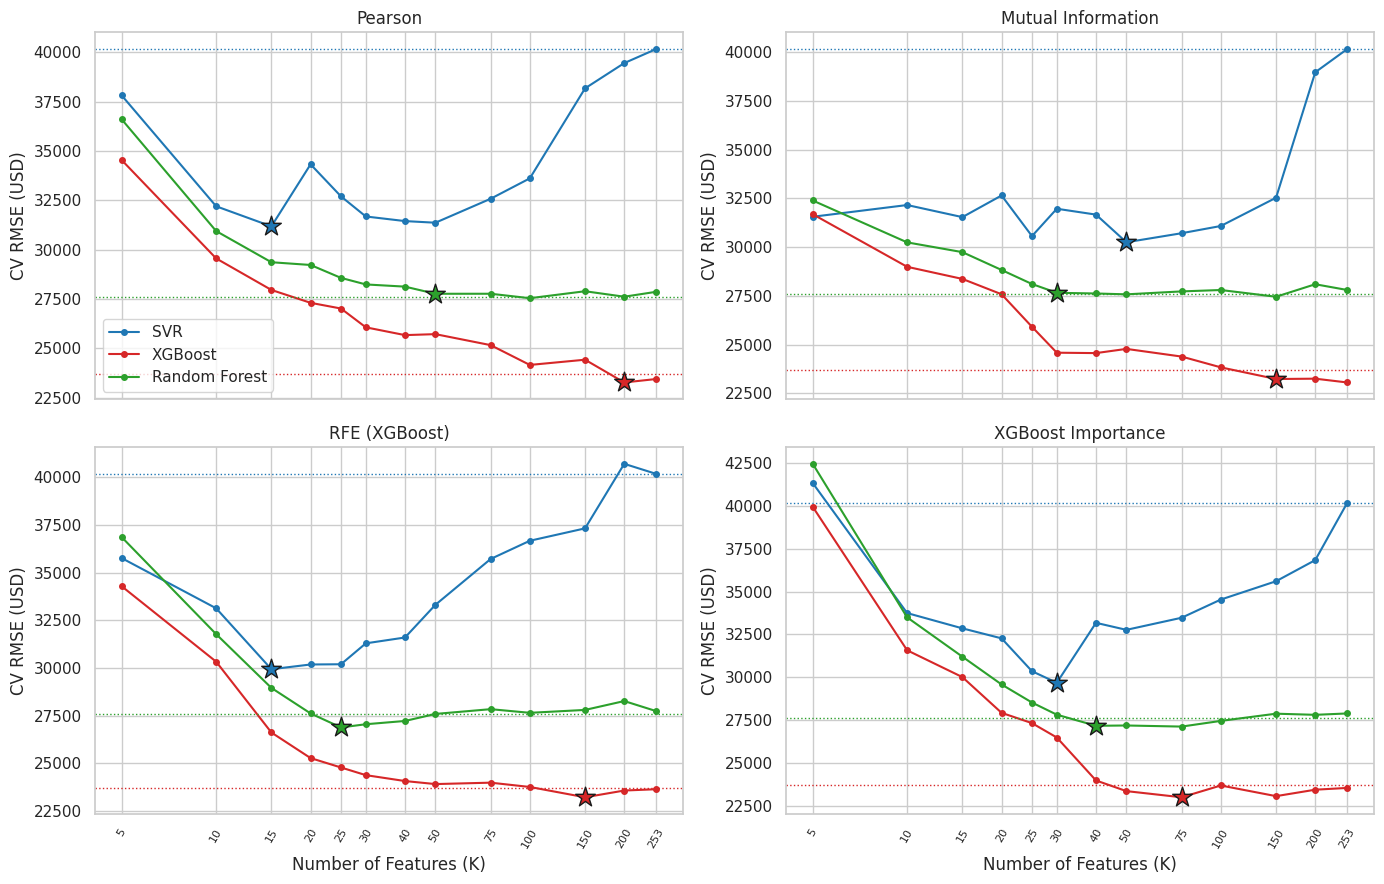

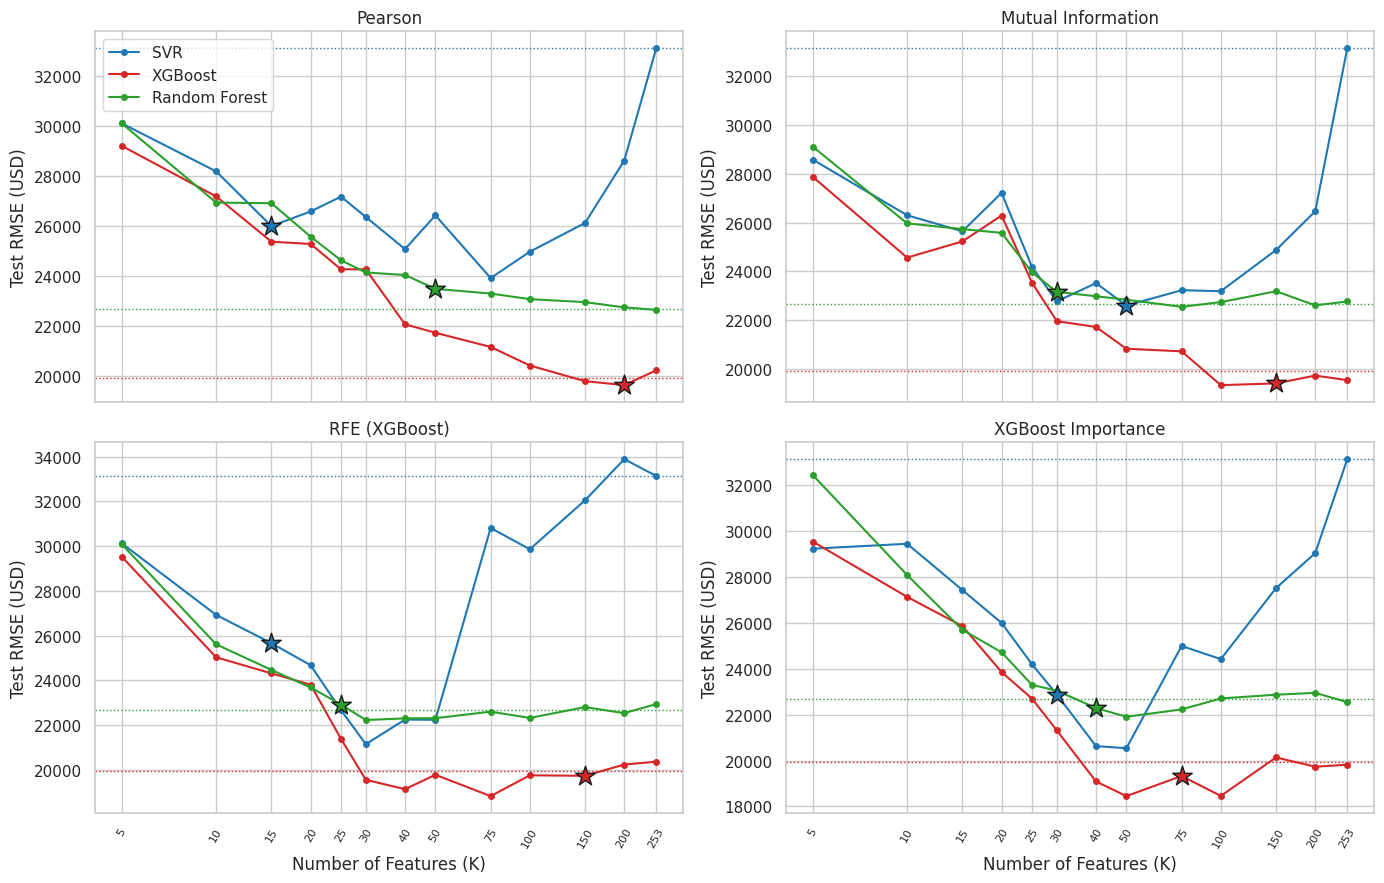

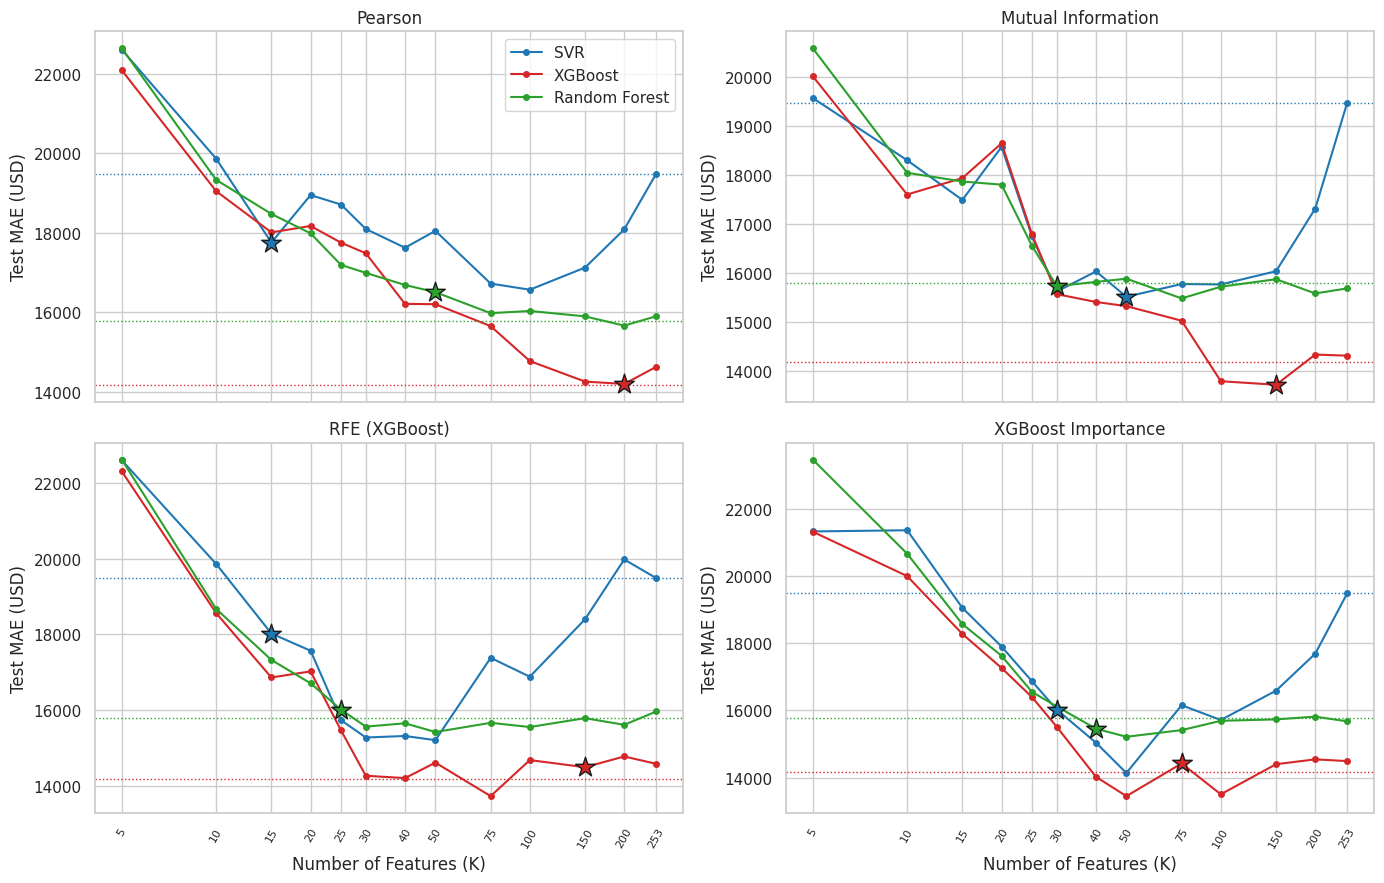

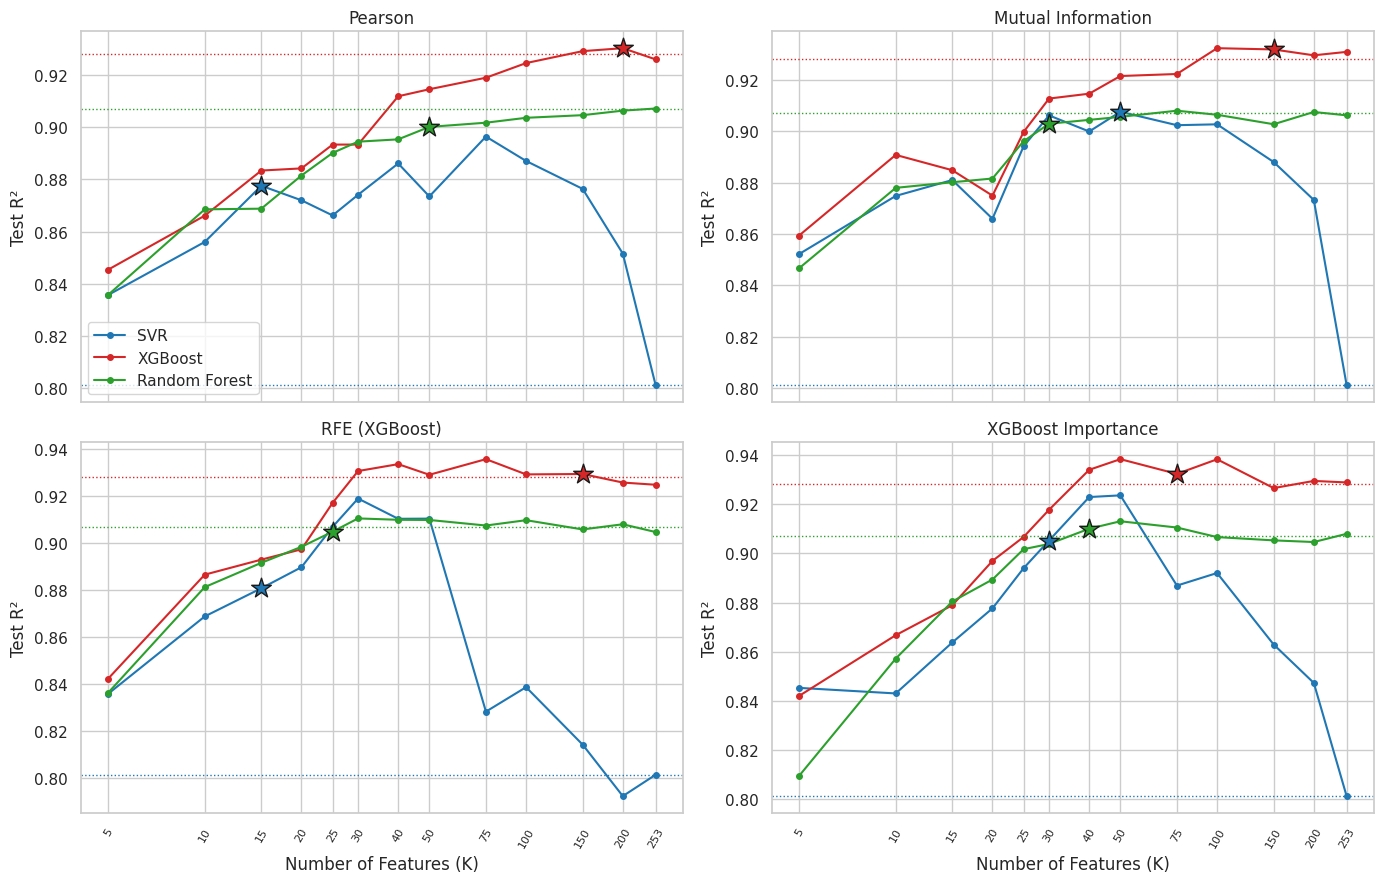

In [ ]:
def select_best_k(df, tol=TOLERANCE):
    picks = []
    for (method, model), g in df.groupby(['Method', 'Model']):
        g = g.sort_values('Num_Features')
        row = g[g.CV_RMSE <= g.CV_RMSE.min() * (1 + tol)].iloc[0].copy()
        row['K_at_min_CV'] = g.loc[g.CV_RMSE.idxmin(), 'Num_Features']
        picks.append(row)
    return pd.DataFrame(picks).reset_index(drop=True)

best_by_method = select_best_k(fs_results)
COLORS = dict(zip(MODEL_NAMES, ['#1f77b4', '#d62728', '#2ca02c']))
base_idx = baseline_df.set_index('Model')

def plot_metric_vs_k(metric, ylabel, fname, baseline_col=None):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    for ax, method in zip(axes.ravel(), RANKERS):
        for name in MODEL_NAMES:
            g = fs_results[(fs_results.Method == method) & (fs_results.Model == name)].sort_values('Num_Features')
            ax.plot(g.Num_Features, g[metric], marker='o', ms=4, color=COLORS[name], label=name)
            if baseline_col: ax.axhline(base_idx.loc[name, baseline_col], color=COLORS[name], ls=':', lw=1)
            b = best_by_method[(best_by_method.Method == method) & (best_by_method.Model == name)].iloc[0]
            ax.scatter(b.Num_Features, g.loc[g.Num_Features == b.Num_Features, metric].iloc[0], marker='*', s=220, color=COLORS[name], edgecolor='k', zorder=5)
        ax.set_xscale('log'); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST, rotation=60, fontsize=8)
        ax.minorticks_off(); ax.set_title(method); ax.set_ylabel(ylabel)
    for ax in axes[1]: ax.set_xlabel('Number of Features (K)')
    axes[0, 0].legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

plot_metric_vs_k('CV_RMSE', 'CV RMSE (USD)', 'chart1a_cv_rmse_vs_k.png', baseline_col='CV_RMSE')
plot_metric_vs_k('RMSE', 'Test RMSE (USD)', 'chart1b_test_rmse_vs_k.png', baseline_col='RMSE')
plot_metric_vs_k('MAE', 'Test MAE (USD)', 'chart2_test_mae_vs_k.png', baseline_col='MAE')
plot_metric_vs_k('R2', 'Test R²', 'chart3_test_r2_vs_k.png', baseline_col='R2')

## 15. Best Feature Configuration
K tốt nhất theo CV (tolerance 1%) cho từng (phương pháp, model). Với mỗi model, cấu hình Feature Selection tốt nhất là phương pháp có CV RMSE thấp nhất trong các cấu hình đã chọn.

In [ ]:
best_table = best_by_method[['Method', 'Model', 'Num_Features', 'K_at_min_CV', 'CV_RMSE', 'CV_RMSE_std', 'RMSE', 'MAE', 'R2', 'Training_Time']].rename(columns={'Num_Features': 'Best_K'})
display(best_table.sort_values(['Model', 'CV_RMSE']))
best_per_model = best_by_method.loc[best_by_method.groupby('Model').CV_RMSE.idxmin()].set_index('Model').loc[MODEL_NAMES]
best_per_model[['Method', 'Num_Features', 'CV_RMSE', 'RMSE', 'MAE', 'R2']]

,Method,Model,Best_K,K_at_min_CV,CV_RMSE,CV_RMSE_std,RMSE,MAE,R2,Training_Time
6,RFE (XGBoost),Random Forest,25,25,"26,879.1988","3,367.1388","22,918.5296","16,013.1905",0.9049,0.6429
9,XGBoost Importance,Random Forest,40,75,"27,175.1356","3,641.3737","22,289.9000","15,455.4690",0.9101,0.9615
0,Mutual Information,Random Forest,30,150,"27,654.3231","3,723.9606","23,165.1121","15,732.5110",0.9029,0.9239
3,Pearson,Random Forest,50,100,"27,762.9793","3,672.4617","23,497.0198","16,506.4391",0.9000,0.9851
10,XGBoost Importance,SVR,30,30,"29,681.1373","3,413.3086","22,878.4225","16,022.6652",0.9052,0.0871
7,RFE (XGBoost),SVR,15,15,"29,931.4224","3,862.4068","25,662.9187","18,023.8566",0.8808,0.0976
1,Mutual Information,SVR,50,50,"30,248.8948","7,462.6530","22,603.8122","15,515.4772",0.9075,0.1678
4,Pearson,SVR,15,15,"31,179.5827","5,245.0455","26,010.6296","17,753.1419",0.8775,0.0750
11,XGBoost Importance,XGBoost,75,75,"23,009.7398","3,055.5474","19,329.1771","14,421.8092",0.9324,0.2310
8,RFE (XGBoost),XGBoost,150,150,"23,219.1906","3,441.5785","19,734.8465","14,492.5578",0.9295,0.4595


,Method,Num_Features,CV_RMSE,RMSE,MAE,R2
Model,,,,,,
SVR,XGBoost Importance,30,"29,681.1373","22,878.4225","16,022.6652",0.9052
XGBoost,XGBoost Importance,75,"23,009.7398","19,329.1771","14,421.8092",0.9324
Random Forest,RFE (XGBoost),25,"26,879.1988","22,918.5296","16,013.1905",0.9049


## 16. Baseline vs Feature Selection

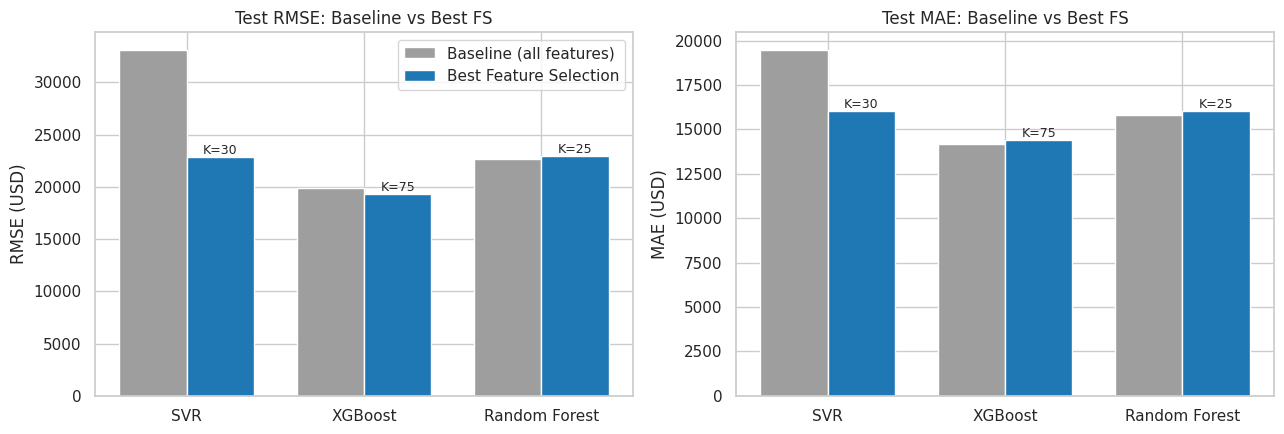

,Model,FS_Method,Best_K,Baseline_RMSE,FS_RMSE,RMSE_Improvement_%,Baseline_MAE,FS_MAE,MAE_Improvement_%,Baseline_R2,FS_R2,R2_Improvement_%,Baseline_CV_RMSE,FS_CV_RMSE,CV_RMSE_Improvement_%,FS_CV_RMSE_std,Baseline_Time,FS_Time,Time_Change_%
0,SVR,XGBoost Importance,30,"33,133.7719","22,878.4225",30.9513,"19,486.6295","16,022.6652",17.7761,0.8012,0.9052,12.9788,"40,169.7863","29,681.1373",26.1108,"3,413.3086",0.1759,0.0871,50.5035
1,XGBoost,XGBoost Importance,75,"19,930.4684","19,329.1771",3.0169,"14,180.1996","14,421.8092",-1.7039,0.9281,0.9324,0.4605,"23,701.0603","23,009.7398",2.9168,"3,055.5474",0.5072,0.2310,54.4623
2,Random Forest,RFE (XGBoost),25,"22,670.0135","22,918.5296",-1.0962,"15,787.3105","16,013.1905",-1.4308,0.9070,0.9049,-0.2261,"27,605.5414","26,879.1988",2.6311,"3,367.1388",2.1197,0.6429,69.6680


In [ ]:
def improvement(base, fs, higher_is_better=False):
    return (fs - base) / abs(base) * 100 if higher_is_better else (base - fs) / base * 100

final_rows = []
for name in MODEL_NAMES:
    b, f = base_idx.loc[name], best_per_model.loc[name]
    final_rows.append({
        'Model': name, 'FS_Method': f.Method, 'Best_K': int(f.Num_Features),
        'Baseline_RMSE': b.RMSE, 'FS_RMSE': f.RMSE, 'RMSE_Improvement_%': improvement(b.RMSE, f.RMSE),
        'Baseline_MAE': b.MAE, 'FS_MAE': f.MAE, 'MAE_Improvement_%': improvement(b.MAE, f.MAE),
        'Baseline_R2': b.R2, 'FS_R2': f.R2, 'R2_Improvement_%': improvement(b.R2, f.R2, True),
        'Baseline_CV_RMSE': b.CV_RMSE, 'FS_CV_RMSE': f.CV_RMSE, 'CV_RMSE_Improvement_%': improvement(b.CV_RMSE, f.CV_RMSE),
        'FS_CV_RMSE_std': f.CV_RMSE_std,
        'Baseline_Time': b.Training_Time, 'FS_Time': f.Training_Time, 'Time_Change_%': improvement(b.Training_Time, f.Training_Time)})
final_df = pd.DataFrame(final_rows)
final_df.to_csv(OUT_DIR / 'final_results.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); w = 0.38; xs = np.arange(len(MODEL_NAMES))
for a, (bc, fc, lab) in zip(ax, [('Baseline_RMSE', 'FS_RMSE', 'RMSE (USD)'), ('Baseline_MAE', 'FS_MAE', 'MAE (USD)')]):
    a.bar(xs - w / 2, final_df[bc], w, label='Baseline (all features)', color='#9e9e9e')
    bars = a.bar(xs + w / 2, final_df[fc], w, label='Best Feature Selection', color='#1f77b4')
    for r, k in zip(bars, final_df.Best_K): a.text(r.get_x() + r.get_width() / 2, r.get_height(), f'K={k}', ha='center', va='bottom', fontsize=9)
    a.set_xticks(xs); a.set_xticklabels(MODEL_NAMES); a.set_ylabel(lab); a.set_title(f'Test {lab.split()[0]}: Baseline vs Best FS')
ax[0].legend(); plt.tight_layout(); plt.savefig(FIG_DIR / 'chart4_baseline_vs_best_fs.png', dpi=150); plt.show()
final_df

## 17. Final Comparison

In [ ]:
summary_methods = best_table.assign(Group=best_table.Method.map({'Pearson': 'Filter', 'Mutual Information': 'Filter', 'RFE (XGBoost)': 'Wrapper', 'XGBoost Importance': 'Embedded'}))
summary_methods = summary_methods[['Group', 'Method', 'Model', 'Best_K', 'RMSE', 'MAE', 'R2', 'CV_RMSE']].sort_values(['Model', 'CV_RMSE'])
display(summary_methods)
print('Trung bình theo nhóm Feature Selection (CV RMSE, Test RMSE, Best K):')
display(summary_methods.groupby('Group')[['CV_RMSE', 'RMSE', 'Best_K']].mean())
print('Trung bình theo phương pháp:')
display(summary_methods.groupby('Method')[['CV_RMSE', 'RMSE', 'Best_K']].mean().sort_values('CV_RMSE'))
display(final_df[['Model', 'Baseline_RMSE', 'FS_RMSE', 'RMSE_Improvement_%', 'Baseline_MAE', 'FS_MAE', 'Baseline_R2', 'FS_R2', 'Best_K']])

,Group,Method,Model,Best_K,RMSE,MAE,R2,CV_RMSE
6,Wrapper,RFE (XGBoost),Random Forest,25,"22,918.5296","16,013.1905",0.9049,"26,879.1988"
9,Embedded,XGBoost Importance,Random Forest,40,"22,289.9000","15,455.4690",0.9101,"27,175.1356"
0,Filter,Mutual Information,Random Forest,30,"23,165.1121","15,732.5110",0.9029,"27,654.3231"
3,Filter,Pearson,Random Forest,50,"23,497.0198","16,506.4391",0.9000,"27,762.9793"
10,Embedded,XGBoost Importance,SVR,30,"22,878.4225","16,022.6652",0.9052,"29,681.1373"
7,Wrapper,RFE (XGBoost),SVR,15,"25,662.9187","18,023.8566",0.8808,"29,931.4224"
1,Filter,Mutual Information,SVR,50,"22,603.8122","15,515.4772",0.9075,"30,248.8948"
4,Filter,Pearson,SVR,15,"26,010.6296","17,753.1419",0.8775,"31,179.5827"
11,Embedded,XGBoost Importance,XGBoost,75,"19,329.1771","14,421.8092",0.9324,"23,009.7398"
8,Wrapper,RFE (XGBoost),XGBoost,150,"19,734.8465","14,492.5578",0.9295,"23,219.1906"


Trung bình theo nhóm Feature Selection (CV RMSE, Test RMSE, Best K):


,CV_RMSE,RMSE,Best_K
Group,,,
Embedded,"26,622.0042","21,499.1665",48.3333
Filter,"27,223.6423","22,389.7280",82.5000
Wrapper,"26,676.6039","22,772.0983",63.3333


Trung bình theo phương pháp:


,CV_RMSE,RMSE,Best_K
Method,,,
XGBoost Importance,"26,622.0042","21,499.1665",48.3333
RFE (XGBoost),"26,676.6039","22,772.0983",63.3333
Mutual Information,"27,044.2189","21,729.7551",76.6667
Pearson,"27,403.0656","23,049.7009",88.3333


,Model,Baseline_RMSE,FS_RMSE,RMSE_Improvement_%,Baseline_MAE,FS_MAE,Baseline_R2,FS_R2,Best_K
0,SVR,"33,133.7719","22,878.4225",30.9513,"19,486.6295","16,022.6652",0.8012,0.9052,30
1,XGBoost,"19,930.4684","19,329.1771",3.0169,"14,180.1996","14,421.8092",0.9281,0.9324,75
2,Random Forest,"22,670.0135","22,918.5296",-1.0962,"15,787.3105","16,013.1905",0.9070,0.9049,25


## 18. Conclusions
Các nhận xét được sinh trực tiếp từ DataFrame kết quả (không nhập tay số liệu) và lưu vào `findings.json` để báo cáo Word dùng lại.

In [ ]:
def curve_summary():
    rows = []
    for (method, name), g in fs_results.groupby(['Method', 'Model']):
        g = g.sort_values('Num_Features').reset_index(drop=True)
        mn, k_min = g.CV_RMSE.min(), g.loc[g.CV_RMSE.idxmin(), 'Num_Features']
        gains = (g.CV_RMSE.shift(1) - g.CV_RMSE) / g.CV_RMSE.shift(1)
        flat = [int(k) for k, gn in zip(g.Num_Features, gains) if pd.notna(gn) and gn < TOLERANCE]
        rows.append({'Method': method, 'Model': name, 'CV_RMSE_K5': g.CV_RMSE.iloc[0], 'CV_RMSE_All': g.CV_RMSE.iloc[-1],
                     'CV_RMSE_Min': mn, 'K_at_Min': int(k_min), 'Gap_All_vs_Min_%': (g.CV_RMSE.iloc[-1] / mn - 1) * 100,
                     'Gap_K5_vs_Min_%': (g.CV_RMSE.iloc[0] / mn - 1) * 100, 'Steps_without_gain': len(flat),
                     'U_shape': bool(k_min < g.Num_Features.max() and g.CV_RMSE.iloc[-1] > mn * (1 + TOLERANCE))})
    return pd.DataFrame(rows)
curve_df = curve_summary()
display(curve_df)

def build_findings():
    f = {}
    chg = lambda v: f'sai số giảm {v:.2f}%' if v > 0 else f'sai số tăng {-v:.2f}%'
    tchg = lambda v: f'giảm {v:.0f}%' if v > 0 else f'tăng {-v:.0f}%'
    n_imp = int((final_df['RMSE_Improvement_%'] > 0).sum())
    f['q8_fs_vs_baseline'] = (f'Theo Test RMSE, Feature Selection tốt nhất (chọn bằng CV) cải thiện Baseline ở {n_imp}/{len(final_df)} model: ' +
        '; '.join(f"{r.Model} {chg(r['RMSE_Improvement_%'])} (K={r.Best_K}, {r.FS_Method})" for _, r in final_df.iterrows()) +
        '. Theo CV RMSE: ' + '; '.join(f"{r.Model} {chg(r['CV_RMSE_Improvement_%'])}" for _, r in final_df.iterrows()) + '.')
    g_model = summary_methods.groupby('Model')
    f['q_best_model'] = 'Model có Test RMSE thấp nhất sau FS: ' + final_df.loc[final_df.FS_RMSE.idxmin(), 'Model'] + f" (RMSE = {final_df.FS_RMSE.min():,.0f} USD, R² = {final_df.loc[final_df.FS_RMSE.idxmin(), 'FS_R2']:.4f}); Baseline tốt nhất: " + baseline_df.loc[baseline_df.RMSE.idxmin(), 'Model'] + f" (RMSE = {baseline_df.RMSE.min():,.0f} USD)."
    by_method = summary_methods.groupby('Method')[['CV_RMSE', 'RMSE', 'Best_K']].mean().sort_values('CV_RMSE')
    f['q_best_method'] = 'Xếp theo CV RMSE trung bình trên 3 model: ' + '; '.join(f"{m} (CV RMSE {r.CV_RMSE:,.0f}, Test RMSE {r.RMSE:,.0f}, K trung bình {r.Best_K:.0f})" for m, r in by_method.iterrows()) + '.'
    f['q_best_k'] = '; '.join(f"{r.Model}: K={r.Best_K} ({r.FS_Method})" for _, r in final_df.iterrows())
    sens = curve_df.groupby('Model')['Gap_K5_vs_Min_%'].median().sort_values(ascending=False)
    f['q_sensitivity'] = 'Mức tăng CV RMSE khi chỉ giữ 5 feature so với điểm tốt nhất (trung vị 4 phương pháp): ' + '; '.join(f'{m} +{v:.1f}%' for m, v in sens.items()) + f'. Model nhạy nhất: {sens.index[0]}; ít nhạy nhất: {sens.index[-1]}.'
    f['q_stability'] = 'Độ biến thiên CV RMSE giữa các fold ở cấu hình chọn (std/mean): ' + '; '.join(f"{r.Model} {r.FS_CV_RMSE_std / r.FS_CV_RMSE * 100:.1f}%" for _, r in final_df.iterrows()) + '.'
    u = curve_df[curve_df.U_shape]
    f['q_u_shape'] = (f'Có {len(u)}/{len(curve_df)} cặp (phương pháp, model) mà CV RMSE ở toàn bộ feature cao hơn mức thấp nhất hơn {TOLERANCE:.0%} (dạng giảm rồi tăng): ' +
        '; '.join(f"{r.Model}/{r.Method} (tốt nhất tại K={r.K_at_Min}, toàn bộ feature kém {r['Gap_All_vs_Min_%']:.1f}%)" for _, r in u.iterrows()) + '.') if len(u) else 'Không có cặp nào có CV RMSE ở toàn bộ feature cao hơn mức thấp nhất quá tolerance.'
    f['q_noise'] = ('Các cặp trên cho thấy bỏ bớt feature giúp giảm sai số, tức có dấu hiệu feature nhiễu/dư thừa với model đó.' if len(u) else 'Chưa thấy bằng chứng rõ về feature nhiễu: thêm feature không làm CV RMSE xấu đi quá tolerance.')
    f['q_no_gain'] = '; '.join(f"{n}: {int(g.Steps_without_gain.sum())}/{len(g) * (len(K_LIST) - 1)} bước tăng K có mức cải thiện CV RMSE < {TOLERANCE:.0%}" for n, g in curve_df.groupby('Model')) + '.'
    near = final_df[final_df['CV_RMSE_Improvement_%'] > -TOLERANCE * 100].copy()
    f['q_same_perf'] = '; '.join(f"{r.Model}: giảm từ {N_FEATURES} xuống {r.Best_K} feature (-{(1 - r.Best_K / N_FEATURES) * 100:.0f}%) với CV RMSE {chg(r['CV_RMSE_Improvement_%'])}, Test RMSE {chg(r['RMSE_Improvement_%'])} so với baseline" for _, r in final_df.iterrows()) + '.'
    f['q_time'] = '; '.join(f"{r.Model}: {r.Baseline_Time:.3f}s -> {r.FS_Time:.3f}s ({tchg(r['Time_Change_%'])})" for _, r in final_df.iterrows()) + ' (thời gian fit một lần trên toàn bộ train, đo trong notebook; có nhiễu do tải máy).'
    f['q_complexity'] = f'Số feature giảm từ {N_FEATURES} xuống ' + ', '.join(f"{r.Best_K} ({r.Model})" for _, r in final_df.iterrows()) + '; mô hình dùng ít đầu vào hơn, dễ diễn giải hơn.'
    f['rfecv'] = f'RFECV (XGBoost, 3-fold CV trên train) tự chọn {RFECV_N} feature, so với K của đường cong RFE ở bảng best_K.'
    f['timing_rank'] = f'Thời gian xếp hạng trên train: Pearson {t_p:.2f}s, MI {t_m:.2f}s, XGBoost importance {t_x:.2f}s, RFE {t_rfe:.1f}s.'
    return f
findings = build_findings()
json.dump({'findings': findings, 'n_features': N_FEATURES, 'k_list': K_LIST, 'rfecv_n': RFECV_N, 'tolerance': TOLERANCE,
           'n_train': len(X_train), 'n_test': len(X_test), 'n_outliers_removed': int(outlier_mask.sum()),
           'rank_time': {'Pearson': t_p, 'Mutual Information': t_m, 'XGBoost Importance': t_x, 'RFE (XGBoost)': t_rfe, 'RFECV': t_rfecv},
           'best_params': {k: {a: (float(b) if hasattr(b, 'item') else b) for a, b in v.items()} for k, v in best_params.items()}},
          open(OUT_DIR / 'findings.json', 'w'), ensure_ascii=False, indent=1)
curve_df.to_csv(OUT_DIR / 'curve_summary.csv', index=False)
display(Markdown('\n'.join(f'- **{k}**: {v}' for k, v in findings.items())))

,Method,Model,CV_RMSE_K5,CV_RMSE_All,CV_RMSE_Min,K_at_Min,Gap_All_vs_Min_%,Gap_K5_vs_Min_%,Steps_without_gain,U_shape
0,Mutual Information,Random Forest,"32,393.4157","27,799.0263","27,452.3300",150,1.2629,17.9988,5,True
1,Mutual Information,SVR,"31,558.6169","40,169.7863","30,248.8948",50,32.7975,4.3298,9,True
2,Mutual Information,XGBoost,"31,689.4454","23,052.2774","23,052.2774",253,0.0000,37.4677,4,False
3,Pearson,Random Forest,"36,602.5889","27,862.8662","27,537.8463",100,1.1803,32.9174,7,True
4,Pearson,SVR,"37,815.3769","40,169.7863","31,179.5827",15,28.8336,21.2825,8,True
5,Pearson,XGBoost,"34,537.8736","23,442.0706","23,266.6349",200,0.7540,48.4438,3,False
6,RFE (XGBoost),Random Forest,"36,854.4025","27,734.9279","26,879.1988",25,3.1836,37.1112,7,True
7,RFE (XGBoost),SVR,"35,755.5084","40,169.7863","29,931.4224",15,34.2061,19.4581,9,True
8,RFE (XGBoost),XGBoost,"34,278.6561","23,641.5569","23,219.1906",150,1.8190,47.6307,5,True
9,XGBoost Importance,Random Forest,"42,440.1561","27,894.8086","27,129.2000",75,2.8221,56.4372,6,True


- **q8_fs_vs_baseline**: Theo Test RMSE, Feature Selection tốt nhất (chọn bằng CV) cải thiện Baseline ở 2/3 model: SVR sai số giảm 30.95% (K=30, XGBoost Importance); XGBoost sai số giảm 3.02% (K=75, XGBoost Importance); Random Forest sai số tăng 1.10% (K=25, RFE (XGBoost)). Theo CV RMSE: SVR sai số giảm 26.11%; XGBoost sai số giảm 2.92%; Random Forest sai số giảm 2.63%.
- **q_best_model**: Model có Test RMSE thấp nhất sau FS: XGBoost (RMSE = 19,329 USD, R² = 0.9324); Baseline tốt nhất: XGBoost (RMSE = 19,930 USD).
- **q_best_method**: Xếp theo CV RMSE trung bình trên 3 model: XGBoost Importance (CV RMSE 26,622, Test RMSE 21,499, K trung bình 48); RFE (XGBoost) (CV RMSE 26,677, Test RMSE 22,772, K trung bình 63); Mutual Information (CV RMSE 27,044, Test RMSE 21,730, K trung bình 77); Pearson (CV RMSE 27,403, Test RMSE 23,050, K trung bình 88).
- **q_best_k**: SVR: K=30 (XGBoost Importance); XGBoost: K=75 (XGBoost Importance); Random Forest: K=25 (RFE (XGBoost))
- **q_sensitivity**: Mức tăng CV RMSE khi chỉ giữ 5 feature so với điểm tốt nhất (trung vị 4 phương pháp): XGBoost +48.0%; Random Forest +35.0%; SVR +20.4%. Model nhạy nhất: XGBoost; ít nhạy nhất: SVR.
- **q_stability**: Độ biến thiên CV RMSE giữa các fold ở cấu hình chọn (std/mean): SVR 11.5%; XGBoost 13.3%; Random Forest 12.5%.
- **q_u_shape**: Có 10/12 cặp (phương pháp, model) mà CV RMSE ở toàn bộ feature cao hơn mức thấp nhất hơn 1% (dạng giảm rồi tăng): Random Forest/Mutual Information (tốt nhất tại K=150, toàn bộ feature kém 1.3%); SVR/Mutual Information (tốt nhất tại K=50, toàn bộ feature kém 32.8%); Random Forest/Pearson (tốt nhất tại K=100, toàn bộ feature kém 1.2%); SVR/Pearson (tốt nhất tại K=15, toàn bộ feature kém 28.8%); Random Forest/RFE (XGBoost) (tốt nhất tại K=25, toàn bộ feature kém 3.2%); SVR/RFE (XGBoost) (tốt nhất tại K=15, toàn bộ feature kém 34.2%); XGBoost/RFE (XGBoost) (tốt nhất tại K=150, toàn bộ feature kém 1.8%); Random Forest/XGBoost Importance (tốt nhất tại K=75, toàn bộ feature kém 2.8%); SVR/XGBoost Importance (tốt nhất tại K=30, toàn bộ feature kém 35.3%); XGBoost/XGBoost Importance (tốt nhất tại K=75, toàn bộ feature kém 2.4%).
- **q_noise**: Các cặp trên cho thấy bỏ bớt feature giúp giảm sai số, tức có dấu hiệu feature nhiễu/dư thừa với model đó.
- **q_no_gain**: Random Forest: 25/48 bước tăng K có mức cải thiện CV RMSE < 1%; SVR: 32/48 bước tăng K có mức cải thiện CV RMSE < 1%; XGBoost: 15/48 bước tăng K có mức cải thiện CV RMSE < 1%.
- **q_same_perf**: SVR: giảm từ 253 xuống 30 feature (-88%) với CV RMSE sai số giảm 26.11%, Test RMSE sai số giảm 30.95% so với baseline; XGBoost: giảm từ 253 xuống 75 feature (-70%) với CV RMSE sai số giảm 2.92%, Test RMSE sai số giảm 3.02% so với baseline; Random Forest: giảm từ 253 xuống 25 feature (-90%) với CV RMSE sai số giảm 2.63%, Test RMSE sai số tăng 1.10% so với baseline.
- **q_time**: SVR: 0.176s -> 0.087s (giảm 51%); XGBoost: 0.507s -> 0.231s (giảm 54%); Random Forest: 2.120s -> 0.643s (giảm 70%) (thời gian fit một lần trên toàn bộ train, đo trong notebook; có nhiễu do tải máy).
- **q_complexity**: Số feature giảm từ 253 xuống 30 (SVR), 75 (XGBoost), 25 (Random Forest); mô hình dùng ít đầu vào hơn, dễ diễn giải hơn.
- **rfecv**: RFECV (XGBoost, 3-fold CV trên train) tự chọn 118 feature, so với K của đường cong RFE ở bảng best_K.
- **timing_rank**: Thời gian xếp hạng trên train: Pearson 0.05s, MI 1.40s, XGBoost importance 0.58s, RFE 4.7s.

## 19. Export Experiment Log
Mỗi dòng nhật ký là một thí nghiệm thực tế đã chạy trong notebook; cột `Decision` được gán theo quy tắc dựa trên CV (xem sheet `Decision_Rules` trong file Excel).

In [ ]:
def save_experiment_log():
    today = datetime.now().strftime('%Y-%m-%d')
    rows = []
    def add(stage, method, model, k, feats, m=None, status='Hoàn thành', obs='', decision='Giữ', cv_m=None, params=''):
        m = {} if m is None else m
        cv_m = {} if cv_m is None else cv_m
        rows.append({'Date': today, 'Stage': stage, 'Method': method, 'Model': model, 'Num_Features': k, 'Features': feats,
                     'RMSE': m['RMSE'] if 'RMSE' in m else None, 'MAE': m['MAE'] if 'MAE' in m else None, 'R2': m['R2'] if 'R2' in m else None, 'Training_Time': m['Training_Time'] if 'Training_Time' in m else None,
                     'Status': status, 'Observation': obs, 'Decision': decision,
                     'CV_RMSE': cv_m['CV_RMSE'] if 'CV_RMSE' in cv_m else None, 'CV_MAE': cv_m['CV_MAE'] if 'CV_MAE' in cv_m else None, 'CV_R2': cv_m['CV_R2'] if 'CV_R2' in cv_m else None, 'Params': params})
    add('Preprocessing', 'Clean + Impute + One-hot', '-', N_FEATURES, 'All',
        obs=f'{len(X_train)} train / {len(X_test)} test; loại {int(outlier_mask.sum())} outlier; {N_FEATURES} feature sau encoding; preprocessor fit trên train')
    for _, r in tuning_df.iterrows():
        add('Hyperparameter Tuning', 'GridSearchCV 5-fold (All features)', r.Model, N_FEATURES, 'All',
            obs=f'Best params {r.Best_Params}; CV RMSLE = {r.CV_RMSLE:.4f}', params=str(r.Best_Params))
    for _, r in baseline_df.iterrows():
        add('Baseline', 'All features', r.Model, N_FEATURES, 'All', m=r, cv_m=r,
            obs=f'Baseline; CV RMSE = {r.CV_RMSE:,.0f}; Test R2 = {r.R2:.4f}', decision='Giữ', params=r.Params)
    for method, order in final_order.items():
        add('Feature Ranking', method, '-' if 'Pearson' in method or 'Mutual' in method else 'XGBoost', N_FEATURES, ', '.join(order[:10]),
            obs=f'Top 10 feature theo {method}; ranking tính chỉ trên train')
    add('Feature Ranking', 'RFECV (XGBoost, 3-fold)', 'XGBoost', RFECV_N, ', '.join(X_train.columns[rfecv.support_][:10]) + ' ...',
        obs=f'RFECV tự chọn {RFECV_N} feature (tham khảo); {t_rfecv:.0f}s', decision='Giữ')
    chosen = best_by_method.set_index(['Method', 'Model']).Num_Features.to_dict()
    overall = {(r.FS_Method, r.Model) for _, r in final_df.iterrows()}
    base_rmse = base_idx.RMSE.to_dict()
    for _, r in fs_results.iterrows():
        bk = chosen[(r.Method, r.Model)]
        cv_min = fs_results[(fs_results.Method == r.Method) & (fs_results.Model == r.Model)].CV_RMSE.min()
        within = r.CV_RMSE <= cv_min * (1 + TOLERANCE)
        if r.Num_Features == bk:
            decision = 'Chọn làm best configuration' if (r.Method, r.Model) in overall else 'Giữ'
            note = 'K nhỏ nhất trong tolerance 1% của CV RMSE tốt nhất'
        elif r.Num_Features < bk:
            decision, note = 'Tiếp tục thử', 'CV RMSE chưa nằm trong tolerance 1%'
        elif within:
            decision, note = 'Loại', 'Tương đương trong tolerance nhưng nhiều feature hơn'
        else:
            decision, note = 'Loại', 'CV RMSE kém hơn mức tốt nhất quá tolerance'
        k = int(r.Num_Features)
        feats = f'All ({N_FEATURES})' if k == N_FEATURES else ', '.join(final_order[r.Method][:k])
        add('Feature Selection', r.Method, r.Model, k, feats, m=r, cv_m=r,
            obs=f'{note}; CV RMSE = {r.CV_RMSE:,.0f}; Test RMSE {(r.RMSE / base_rmse[r.Model] - 1) * 100:+.2f}% so với baseline', decision=decision,
            params=str(best_params[r.Model]))
    for _, r in final_df.iterrows():
        add('Final Comparison', r.FS_Method, r.Model, r.Best_K, f'Top {r.Best_K} theo {r.FS_Method}',
            m={'RMSE': r.FS_RMSE, 'MAE': r.FS_MAE, 'R2': r.FS_R2, 'Training_Time': r.FS_Time},
            cv_m={'CV_RMSE': r.FS_CV_RMSE}, obs=f"RMSE {r['RMSE_Improvement_%']:+.2f}%, MAE {r['MAE_Improvement_%']:+.2f}%, R2 {r['R2_Improvement_%']:+.2f}% so với baseline",
            decision='Chọn làm best configuration')
    log = pd.DataFrame(rows)
    log.insert(0, 'Experiment_ID', [f'EXP{i:03d}' for i in range(1, len(log) + 1)])
    log.to_csv(OUT_DIR / 'experiment_log.csv', index=False)

    rules = pd.DataFrame({'Decision': ['Chọn làm best configuration', 'Giữ', 'Tiếp tục thử', 'Loại'], 'Quy tắc': [
        'Cấu hình có K nhỏ nhất trong tolerance 1% của CV RMSE tốt nhất, và là cấu hình có CV RMSE thấp nhất của model đó giữa các phương pháp FS',
        'Mốc/phiên bản được giữ lại (baseline, tuning, ranking) hoặc K tốt nhất của một phương pháp nhưng không phải tốt nhất của model',
        'K nhỏ hơn K được chọn: CV RMSE chưa vào tolerance 1%, phải tăng K',
        'K lớn hơn K được chọn: tương đương trong tolerance nhưng phức tạp hơn, hoặc kém hơn quá tolerance']})
    with pd.ExcelWriter(OUT_DIR / 'Experiment_Log.xlsx', engine='openpyxl') as xw:
        log.to_excel(xw, sheet_name='Experiment_Log', index=False); rules.to_excel(xw, sheet_name='Decision_Rules', index=False)
        from openpyxl.styles import Font, PatternFill, Alignment
        for ws in xw.book.worksheets:
            for c in ws[1]:
                c.font = Font(name='Arial', bold=True, color='FFFFFF'); c.fill = PatternFill('solid', fgColor='1F4E78')
                c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
            for row in ws.iter_rows(min_row=2):
                for c in row: c.font = Font(name='Arial', size=10)
            ws.freeze_panes = 'A2'; ws.auto_filter.ref = ws.dimensions
        ws = xw.sheets['Experiment_Log']
        widths = dict(A=12, B=11, C=20, D=26, E=14, F=13, G=36, H=12, I=12, J=9, K=13, L=11, M=55, N=26, O=12, P=12, Q=9, R=30)
        for col, w in widths.items(): ws.column_dimensions[col].width = w
        for row in ws.iter_rows(min_row=2):
            for c in row:
                if c.column_letter in 'HIL' and c.value is not None: c.number_format = '#,##0.00' if c.column_letter != 'L' else '0.000'
                if c.column_letter in 'OP' and c.value is not None: c.number_format = '#,##0.00'
                if c.column_letter == 'J' and c.value is not None: c.number_format = '0.0000'
                if c.column_letter == 'Q' and c.value is not None: c.number_format = '0.0000'
        xw.sheets['Decision_Rules'].column_dimensions['A'].width = 30; xw.sheets['Decision_Rules'].column_dimensions['B'].width = 120
    return log

experiment_log = save_experiment_log()
best_feats = best_by_method[['Method', 'Model', 'Num_Features']].copy()
best_feats['Features'] = [', '.join(final_order[m][:k]) for m, k in zip(best_feats.Method, best_feats.Num_Features)]
best_feats.to_csv(OUT_DIR / 'best_features.csv', index=False)
print(experiment_log.shape); print(experiment_log.Decision.value_counts().to_string())
print(sorted(p.name for p in OUT_DIR.iterdir()))

(171, 18)
Decision
Tiếp tục thử                   77
Loại                           67
Giữ                            21
Chọn làm best configuration     6
['Experiment_Log.xlsx', 'baseline_results.csv', 'best_features.csv', 'curve_summary.csv', 'experiment_log.csv', 'feature_rankings.csv', 'feature_selection_results.csv', 'figures', 'final_results.csv', 'findings.json']
